# Whole-Brain Deviation Burden + Hippocampal Volume

Secondary analyses, same cohort and group definitions as `composite_figures.ipynb`.

Design notes:
- Morphometry z-scores from `../data/centilebrain_zscores/` (FreeSurfer 7.3.2 on all 355 subjects, T1w only).
- Arcuate uses both hemispheres (AF_L + AF_R), in the tract-level and node-level burden.
- Two burden measures per domain: number of regions with |z|>2 (equivalently, the proportion) and mean |z|.
- Missing columns raise an error instead of being skipped.
- Hippocampal volume z-scores on their own, with mesial temporal sclerosis (MTS) as a positive control.

Burden domains:
- **Whole-brain morphometry**: 82 ROIs (68 cortical thickness + 14 subcortical volume).
- **Tract-level tractometry**: 18 bilateral tract x metric composites (9 tracts x FA/MD).
- **Node-level tractometry**: every node of the 15 individual tracts used in the paper (AF, C, CST, F, IFOF, UF
  left and right, plus the 3 commissural tracts) x FA/MD x 100 nodes = 3,000 values. Adjacent nodes are highly
  autocorrelated, so this count reflects the length of abnormal stretches more than the number of independent
  abnormal structures.

Hippocampal positive control:
- MTS group restricted to unilateral MTS with no other lesion type (12 of the 16 MTS patients).
- Non-lesional = `mri_lesion == 0`, asserted to have no lesion flag.
- Asymmetry listed first (the natural measure for a unilateral lesion); paired test on the same 12 patients.
- The supplementary figure (Figure S5 of the manuscript) shows burden, the MTS paired comparison and hippocampal asymmetry.

Outputs (`../outputs/`): `table_burden_auc.csv`, `table_hippocampus_auc.csv`, `table_burden_nonlesional.csv`, `figure_supp_burden_hippocampus.pdf/png`.

In [1]:
import pandas as pd
import numpy as np
from scipy.stats import mannwhitneyu, wilcoxon
from statsmodels.stats.multitest import multipletests
import warnings
warnings.filterwarnings('ignore')
RNG_SEED = 42

def mwu_auc(a, b):
    a = np.asarray(a); b = np.asarray(b)
    U, p = mannwhitneyu(a, b, alternative='two-sided')
    return U / (len(a) * len(b)), p

def bootstrap_auc_ci(a, b, n_boot=5000, seed=RNG_SEED):
    rng = np.random.default_rng(seed)
    a = np.asarray(a); b = np.asarray(b)
    na, nb = len(a), len(b)
    aucs = np.empty(n_boot)
    for k in range(n_boot):
        bs_a = rng.choice(a, size=na, replace=True)
        bs_b = rng.choice(b, size=nb, replace=True)
        U, _ = mannwhitneyu(bs_a, bs_b, alternative='two-sided')
        aucs[k] = U / (na * nb)
    return np.percentile(aucs, 2.5), np.percentile(aucs, 97.5)

def fold_auc(auc, lo, hi):
    """max(AUC, 1-AUC) with the CI flipped to match, as in the manuscript."""
    return (auc, lo, hi) if auc >= 0.5 else (1 - auc, 1 - hi, 1 - lo)

def require(cols, available, what):
    missing = [c for c in cols if c not in available]
    assert not missing, f'{what}: columns not found: {missing}'

comparisons = [('Epilepsy', 'FS', 'Epilepsy', 'Functional Seizures'),
               ('Focal', 'Generalized', 'Focal', 'Generalized'),
               ('DR', 'DS', 'Drug-Resistant', 'Drug-Responsive')]

def split_groups(df, g1='group_1', g2='group_2'):
    epi = df[df[g2].isin(['drug-resistant', 'drug-responsive'])]
    return {'Epilepsy': epi, 'FS': df[df[g1] == 'pnee'],
            'Focal': epi[epi[g1] == 'focal'], 'Generalized': epi[epi[g1] == 'generalized'],
            'DR': epi[epi[g2] == 'drug-resistant'], 'DS': epi[epi[g2] == 'drug-responsive']}

## 1. Morphometry (82 ROIs)

In [2]:
base = '../data'
morph_base = '../data/centilebrain_zscores'  # FreeSurfer 7.3.2 (T1w only) -> CentileBrain z-scores
meta = pd.read_csv(f'{base}/metadata_drug_responsiveness.csv').rename(columns={'record_id': 'SubjectID'})
meta = meta.drop_duplicates(subset='SubjectID', keep='first')  # one subject appears twice in the metadata; keep the first row, as elsewhere
lesion_types = ['lesion_mts', 'lesion_stroke', 'lesion_tumor', 'lesion_fcd', 'lesion_tbi', 'lesion_ich',
                'lesion_encephalocele', 'lesion_heterotopia', 'lesion_pmg', 'lesion_cavernoma',
                'lesion_atrophy', 'lesion_other']

# Sex is defined by which CentileBrain model file a subject is in (the files' own 'sex' column is 1 for everyone).
ct = pd.concat([pd.read_csv(f'{morph_base}/zscore_CorticalThickness_male.csv').assign(sex='M'),
                pd.read_csv(f'{morph_base}/zscore_CorticalThickness_female.csv').assign(sex='F')], ignore_index=True)
sv = pd.concat([pd.read_csv(f'{morph_base}/zscore_SubcorticalVolume_male.csv'),
                pd.read_csv(f'{morph_base}/zscore_SubcorticalVolume_female.csv')], ignore_index=True)
# CentileBrain's output misspells two DK regions; restore the standard names.
ct = ct.rename(columns=lambda c: c.replace('_entorhil_', '_entorhinal_').replace('_supramargil_', '_supramarginal_'))
both_subs = set(ct['SubjectID']) & set(sv['SubjectID'])
ct = ct[ct['SubjectID'].isin(both_subs)]
sv = sv[sv['SubjectID'].isin(both_subs)]

ct_zcols = [c for c in ct.columns if c.endswith('_thickavg')]
sv_zcols = [c for c in sv.columns if c not in ['SITE', 'SubjectID', 'Vendor', 'FreeSurfer_Version', 'age', 'sex']]
roi_cols = ct_zcols + sv_zcols
assert len(ct_zcols) == 68 and len(sv_zcols) == 14, (len(ct_zcols), len(sv_zcols))

morph = ct.merge(sv[['SubjectID'] + sv_zcols], on='SubjectID', how='inner')
morph = morph.merge(meta[['SubjectID', 'group_1', 'group_2', 'mri_lesion', 'lesion_left', 'lesion_right', 'lesion_bilateral'] + lesion_types],
                    on='SubjectID', how='left')

tract_subs = set(pd.read_csv(f'{base}/node_zscores.csv', usecols=['subject'])['subject'].unique())
morph = morph[morph['SubjectID'].isin(tract_subs)].copy()
sex_meta = morph['SubjectID'].map(meta.set_index('SubjectID')['sex'])
assert (sex_meta == morph['sex']).all(), 'CentileBrain model sex disagrees with metadata sex'

morph['n_abnormal'] = (morph[roi_cols].abs() > 2).sum(axis=1)
morph['mean_abs_z'] = morph[roi_cols].abs().mean(axis=1)

morph_groups = split_groups(morph)
print(f'Morphometry ROIs: {len(roi_cols)}  |  subjects: {len(morph)}')
print('   '.join(f'{k}: {len(v)}' for k, v in morph_groups.items()))

Morphometry ROIs: 82  |  subjects: 355
Epilepsy: 273   FS: 32   Focal: 203   Generalized: 37   DR: 97   DS: 176


## 2. Tractometry (tract-level and node-level)

In [3]:
raw = pd.read_csv(f'{base}/node_zscores.csv')
clin = raw[(raw['cohort'] == 'Clinical') & (raw['scalar'].isin(['dti_fa', 'dti_md']))].copy()
clin = clin[clin['subject'].isin(set(morph['SubjectID']))]
group_cols = meta[['SubjectID', 'group_1', 'group_2']].rename(columns={'SubjectID': 'subject'})

# Tract-level: mean z over nodes per tract, then L/R average -> 18 series (same as composite_figures.ipynb)
clin['feature'] = clin['tract'] + '_' + clin['scalar']
wide = clin.pivot_table(index='subject', columns='feature', values='z_score').reset_index()
wide = wide.merge(group_cols, on='subject', how='left')
bilateral_tracts = {
    'Cingulum': ['C_L', 'C_R'], 'Fornix': ['F_L', 'F_R'], 'Uncinate': ['UF_L', 'UF_R'],
    'Arcuate': ['AF_L', 'AF_R'], 'IFOF': ['IFOF_L', 'IFOF_R'],
    'CC Forceps Major': ['CC_ForcepsMajor'], 'CC Forceps Minor': ['CC_ForcepsMinor'], 'CC Mid': ['CCMid'],
    'CST': ['CST_L', 'CST_R'],
}
bilateral_cols = []
for name, tracts in bilateral_tracts.items():
    for scalar in ['dti_fa', 'dti_md']:
        fc = [f'{t}_{scalar}' for t in tracts]
        require(fc, wide.columns, name)
        col = f'zb_{name}_{scalar}'.replace(' ', '_')
        wide[col] = wide[fc].mean(axis=1)
        bilateral_cols.append(col)
wide['n_abnormal'] = (wide[bilateral_cols].abs() > 2).sum(axis=1)
wide['mean_abs_z'] = wide[bilateral_cols].abs().mean(axis=1)
tract_groups = split_groups(wide)

# Node-level: every node of the individual tracts that make up the 9 tract profiles
indiv_tracts = [t for ts in bilateral_tracts.values() for t in ts]
require(indiv_tracts, set(clin['tract']), 'node-level tracts')
node = clin[clin['tract'].isin(indiv_tracts)]
node_burden = node.groupby('subject').agg(
    n_abnormal=('z_score', lambda s: (s.abs() > 2).sum()),
    mean_abs_z=('z_score', lambda s: s.abs().mean()),
    n_values=('z_score', 'count')).reset_index().merge(group_cols, on='subject', how='left')
node_groups = split_groups(node_burden)

print(f'Tract-level series: {len(bilateral_cols)} (expect 18)')
print(f'Node-level tracts: {len(indiv_tracts)}; values per subject: '
      f"{node_burden['n_values'].min()}-{node_burden['n_values'].max()} (expect {len(indiv_tracts)} x 2 x 100)")
print('   '.join(f'{k}: {len(v)}' for k, v in tract_groups.items()))

Tract-level series: 18 (expect 18)
Node-level tracts: 15; values per subject: 3000-3000 (expect 15 x 2 x 100)
Epilepsy: 273   FS: 32   Focal: 203   Generalized: 37   DR: 97   DS: 176


## 3. Burden AUCs

For each domain and burden measure, Mann-Whitney U between groups, AUC with 5,000-bootstrap CI, reported as
max(AUC, 1-AUC) with the higher group named. Benjamini-Hochberg FDR across the six domain x measure tests
within each comparison.

In [4]:
domains = [('Whole-brain morphometry (82 ROIs)', morph_groups, 82),
           ('Tractometry, tract-level (18 series)', tract_groups, 18),
           (f'Tractometry, node-level ({len(indiv_tracts) * 200:,} values)', node_groups, len(indiv_tracts) * 200)]
measures = [('n_abnormal', 'Regions with |z|>2'), ('mean_abs_z', 'Mean |z|')]

rows = []
for ga, gb, la, lb in comparisons:
    comp_rows = []
    for dname, groups, n_units in domains:
        for col, mlabel in measures:
            a, b = groups[ga][col], groups[gb][col]
            auc, p = mwu_auc(a, b)
            lo, hi = bootstrap_auc_ci(a, b)
            f_auc, f_lo, f_hi = fold_auc(auc, lo, hi)
            if col == 'n_abnormal':
                med = f'{a.median():.0f} vs {b.median():.0f} ({100 * a.median() / n_units:.1f}% vs {100 * b.median() / n_units:.1f}%)'
            else:
                med = f'{a.median():.2f} vs {b.median():.2f}'
            comp_rows.append({'Comparison': f'{la} vs. {lb}', 'Domain': dname, 'Measure': mlabel,
                              'n': f'{len(a)} vs {len(b)}', 'Median (A vs B)': med,
                              'AUC': f_auc, 'CI_lo': f_lo, 'CI_hi': f_hi,
                              'Higher In': la if auc >= 0.5 else lb, 'p': p})
    q = multipletests([r['p'] for r in comp_rows], method='fdr_bh')[1]
    for r, qq in zip(comp_rows, q):
        r['q'] = qq
    rows += comp_rows

burden = pd.DataFrame(rows)
burden['AUC (95% CI)'] = burden.apply(lambda r: f"{r['AUC']:.3f} ({r['CI_lo']:.3f}-{r['CI_hi']:.3f})", axis=1)
burden_table = burden[['Comparison', 'Domain', 'Measure', 'n', 'Median (A vs B)', 'AUC (95% CI)', 'Higher In', 'p', 'q']].copy()
burden_table['p'] = burden_table['p'].round(4)
burden_table['q'] = burden_table['q'].round(4)
burden_table.to_csv('../outputs/table_burden_auc.csv', index=False)
pd.set_option('display.width', 250); pd.set_option('display.max_colwidth', 60)
burden_table

,Comparison,Domain,Measure,n,Median (A vs B),AUC (95% CI),Higher In,p,q
0,Epilepsy vs. Functional Seizures,Whole-brain morphometry (82 ROIs),Regions with |z|>2,273 vs 32,7 vs 5 (8.5% vs 6.1%),0.659 (0.574-0.741),Epilepsy,0.0032,0.0095
1,Epilepsy vs. Functional Seizures,Whole-brain morphometry (82 ROIs),Mean |z|,273 vs 32,0.92 vs 0.84,0.672 (0.581-0.756),Epilepsy,0.0015,0.0088
2,Epilepsy vs. Functional Seizures,"Tractometry, tract-level (18 series)",Regions with |z|>2,273 vs 32,0 vs 0 (0.0% vs 0.0%),0.541 (0.500-0.571),Epilepsy,0.1543,0.2315
3,Epilepsy vs. Functional Seizures,"Tractometry, tract-level (18 series)",Mean |z|,273 vs 32,0.46 vs 0.50,0.505 (0.403-0.615),Functional Seizures,0.9333,0.9333
4,Epilepsy vs. Functional Seizures,"Tractometry, node-level (3,000 values)",Regions with |z|>2,273 vs 32,73 vs 64 (2.4% vs 2.1%),0.603 (0.491-0.710),Epilepsy,0.0564,0.1128
5,Epilepsy vs. Functional Seizures,"Tractometry, node-level (3,000 values)",Mean |z|,273 vs 32,0.69 vs 0.68,0.542 (0.427-0.649),Epilepsy,0.4325,0.5190
6,Focal vs. Generalized,Whole-brain morphometry (82 ROIs),Regions with |z|>2,203 vs 37,6 vs 7 (7.3% vs 8.5%),0.522 (0.426-0.620),Generalized,0.6729,0.7147
7,Focal vs. Generalized,Whole-brain morphometry (82 ROIs),Mean |z|,203 vs 37,0.91 vs 0.92,0.519 (0.425-0.614),Generalized,0.7147,0.7147
8,Focal vs. Generalized,"Tractometry, tract-level (18 series)",Regions with |z|>2,203 vs 37,0 vs 0 (0.0% vs 0.0%),0.534 (0.488-0.574),Focal,0.2285,0.4594
9,Focal vs. Generalized,"Tractometry, tract-level (18 series)",Mean |z|,203 vs 37,0.44 vs 0.46,0.545 (0.444-0.644),Focal,0.3870,0.5805


## 3b. Sex Check for the Epilepsy vs. Functional-Seizure Burden Difference

The functional-seizure group is 78% female vs 47% in epilepsy, and CentileBrain uses separate models by sex.
Female-only and male-only comparisons, a sex-stratified AUC (within-sex pairs pooled), and a rank regression with
sex as a covariate. Syncope vs functional seizures is repeated in women only.

In [5]:
import statsmodels.formula.api as smf
from scipy.stats import rankdata
e, f = morph_groups['Epilepsy'], morph_groups['FS']
syn = morph[morph['group_1'] == 'syncope']
print(pd.crosstab(pd.concat([e.assign(g='Epilepsy'), f.assign(g='FS'), syn.assign(g='Syncope')])['g'],
                  pd.concat([e, f, syn])['sex']))
sex_rows = []
for col, mlabel in measures:
    for sx in ['F', 'M']:
        a, b = e[e['sex'] == sx][col], f[f['sex'] == sx][col]
        auc, p = mwu_auc(a, b)
        sex_rows.append({'Measure': mlabel, 'Test': f'{sx} only: epilepsy vs FS', 'n': f'{len(a)} vs {len(b)}',
                         'AUC': round(auc, 3), 'p': round(p, 4)})
    num = sum(mwu_auc(e[e['sex'] == sx][col], f[f['sex'] == sx][col])[0] * (e['sex'] == sx).sum() * (f['sex'] == sx).sum()
              for sx in ['F', 'M'])
    den = sum((e['sex'] == sx).sum() * (f['sex'] == sx).sum() for sx in ['F', 'M'])
    sex_rows.append({'Measure': mlabel, 'Test': 'Sex-stratified AUC (within-sex pairs pooled)', 'n': f'{len(e)} vs {len(f)}',
                     'AUC': round(num / den, 3), 'p': np.nan})
    d = pd.concat([e, f]).copy()
    d['is_epi'] = d['group_2'].isin(['drug-resistant', 'drug-responsive']).astype(int)
    d['r'] = rankdata(d[col])
    fit = smf.ols('r ~ is_epi + C(sex)', data=d).fit()
    sex_rows.append({'Measure': mlabel, 'Test': 'Rank regression, epilepsy effect adjusted for sex', 'n': f'{len(e)} vs {len(f)}',
                     'AUC': np.nan, 'p': round(fit.pvalues['is_epi'], 4)})
    a, b = syn[syn['sex'] == 'F'][col], f[f['sex'] == 'F'][col]
    auc, p = mwu_auc(a, b)
    sex_rows.append({'Measure': mlabel, 'Test': 'F only: syncope vs FS', 'n': f'{len(a)} vs {len(b)}',
                     'AUC': round(auc, 3), 'p': round(p, 4)})
sex_check = pd.DataFrame(sex_rows)
print(morph[morph['group_1'].isin(['pnee', 'syncope']) | morph['group_2'].isin(['drug-resistant', 'drug-responsive'])]
      .assign(g=lambda x: np.where(x['group_1'] == 'pnee', 'FS', np.where(x['group_1'] == 'syncope', 'Syncope', 'Epilepsy')))
      .groupby(['g', 'sex'])['n_abnormal'].median().unstack('sex').rename_axis(None).to_string())
sex_check

sex         F    M
g                 
Epilepsy  127  146
FS         25    7
Syncope    17    8
sex         F    M
Epilepsy  8.0  6.0
FS        5.0  5.0
Syncope   8.0  4.5


,Measure,Test,n,AUC,p
0,Regions with |z|>2,F only: epilepsy vs FS,127 vs 25,0.661,0.0107
1,Regions with |z|>2,M only: epilepsy vs FS,146 vs 7,0.718,0.0511
2,Regions with |z|>2,Sex-stratified AUC (within-sex pairs pooled),273 vs 32,0.675,NaN
3,Regions with |z|>2,"Rank regression, epilepsy effect adjusted for sex",273 vs 32,NaN,0.0011
4,Regions with |z|>2,F only: syncope vs FS,17 vs 25,0.706,0.0247
5,Mean |z|,F only: epilepsy vs FS,127 vs 25,0.653,0.0159
6,Mean |z|,M only: epilepsy vs FS,146 vs 7,0.796,0.0062
7,Mean |z|,Sex-stratified AUC (within-sex pairs pooled),273 vs 32,0.688,NaN
8,Mean |z|,"Rank regression, epilepsy effect adjusted for sex",273 vs 32,NaN,0.0007
9,Mean |z|,F only: syncope vs FS,17 vs 25,0.633,0.1513


## 4. Calibration: Burden in Each Group

For a well-calibrated normative model, about 4.6% of values in a healthy-like group exceed |z|>2
(about 4 of 82 ROIs). Syncope patients are the closest thing to a healthy reference in this cohort.

In [6]:
syncope = morph[morph['group_1'] == 'syncope']
calib = pd.DataFrame({
    name: {'n': len(df), 'median regions |z|>2 (of 82)': df['n_abnormal'].median(),
           'median mean |z|': round(df['mean_abs_z'].median(), 2)}
    for name, df in list(morph_groups.items()) + [('Syncope', syncope)]
}).T
calib

,n,median regions |z|>2 (of 82),median mean |z|
Epilepsy,273.0,7.0,0.92
FS,32.0,5.0,0.84
Focal,203.0,6.0,0.91
Generalized,37.0,7.0,0.92
DR,97.0,7.0,0.92
DS,176.0,7.0,0.92
Syncope,25.0,6.0,0.89


## 5. Hippocampal Volume Alone

Two measures from the hippocampal volume z-scores: the absolute left-right difference (asymmetry) and the mean of
left and right. Same tests as above, with Benjamini-Hochberg FDR across the two measures within each comparison.

Positive control: epilepsy patients with unilateral mesial temporal sclerosis (MTS) and no other lesion on clinical
MRI vs non-lesional epilepsy patients, and the sclerotic vs contralateral hippocampus within the same MTS patients
(Wilcoxon signed-rank).

In [7]:
morph['hip_mean'] = morph[['Lhippo', 'Rhippo']].mean(axis=1)
morph['hip_min'] = morph[['Lhippo', 'Rhippo']].min(axis=1)
morph['hip_asym'] = (morph['Lhippo'] - morph['Rhippo']).abs()
hip_measures = [('hip_asym', '|Left - Right|'), ('hip_mean', 'Mean of L/R')]
morph_groups = split_groups(morph)  # refresh with the new columns

epi = morph_groups['Epilepsy']
hip_groups = dict(morph_groups)
other_lesion = epi[[c for c in lesion_types if c != 'lesion_mts']].sum(axis=1) > 0
unilateral = (epi['lesion_left'] + epi['lesion_right'] == 1) & (epi['lesion_bilateral'] == 0)
mts_any = epi[epi['lesion_mts'] == 1]
hip_groups['MTS'] = epi[(epi['lesion_mts'] == 1) & unilateral & ~other_lesion]
hip_groups['Non-lesional'] = epi[epi['mri_lesion'] == 0]
assert (hip_groups['Non-lesional'][lesion_types].sum(axis=1) == 0).all(), 'non-lesional patient has a lesion flag'
print(f"MTS in epilepsy cohort: {len(mts_any)}; unilateral with no other lesion: {len(hip_groups['MTS'])}; excluded:")
for _, r in mts_any[~mts_any['SubjectID'].isin(hip_groups['MTS']['SubjectID'])].iterrows():
    why = [c.replace('lesion_', '') for c in lesion_types if c != 'lesion_mts' and r[c] == 1]
    print(f"  {r['SubjectID']}: {', '.join(why) + (' (bilateral)' if r['lesion_bilateral'] == 1 else '')}")
print(f"Non-lesional epilepsy: {len(hip_groups['Non-lesional'])}")
hip_comparisons = comparisons + [('MTS', 'Non-lesional', 'MTS', 'Non-Lesional Epilepsy')]

rows = []
for ga, gb, la, lb in hip_comparisons:
    comp_rows = []
    for col, mlabel in hip_measures:
        a, b = hip_groups[ga][col], hip_groups[gb][col]
        auc, p = mwu_auc(a, b)
        lo, hi = bootstrap_auc_ci(a, b)
        f_auc, f_lo, f_hi = fold_auc(auc, lo, hi)
        comp_rows.append({'Comparison': f'{la} vs. {lb}', 'Measure': mlabel, 'n': f'{len(a)} vs {len(b)}',
                          'Median z (A vs B)': f'{a.median():.2f} vs {b.median():.2f}',
                          'AUC (95% CI)': f'{f_auc:.3f} ({f_lo:.3f}-{f_hi:.3f})',
                          'Higher In': la if auc >= 0.5 else lb, 'p': p})
    q = multipletests([r['p'] for r in comp_rows], method='fdr_bh')[1]
    for r, qq in zip(comp_rows, q):
        r['q'] = qq
    rows += comp_rows

hip_table = pd.DataFrame(rows)
hip_table['p'] = hip_table['p'].round(4)
hip_table['q'] = hip_table['q'].round(4)
hip_table.to_csv('../outputs/table_hippocampus_auc.csv', index=False)
hip_table

MTS in epilepsy cohort: 16; unilateral with no other lesion: 12; excluded: 4 (per-patient lines removed from the saved output)
Non-lesional epilepsy: 184


,Comparison,Measure,n,Median z (A vs B),AUC (95% CI),Higher In,p,q
0,Epilepsy vs. Functional Seizures,|Left - Right|,273 vs 32,0.55 vs 0.41,0.572 (0.479-0.662),Epilepsy,0.1844,0.3688
1,Epilepsy vs. Functional Seizures,Mean of L/R,273 vs 32,-0.01 vs -0.03,0.538 (0.452-0.622),Epilepsy,0.4878,0.4878
2,Focal vs. Generalized,|Left - Right|,203 vs 37,0.61 vs 0.52,0.574 (0.476-0.671),Focal,0.1538,0.1538
3,Focal vs. Generalized,Mean of L/R,203 vs 37,0.16 vs -0.16,0.590 (0.493-0.684),Focal,0.0827,0.1538
4,Drug-Resistant vs. Drug-Responsive,|Left - Right|,97 vs 176,0.58 vs 0.54,0.540 (0.468-0.612),Drug-Resistant,0.2687,0.2786
5,Drug-Resistant vs. Drug-Responsive,Mean of L/R,97 vs 176,-0.07 vs 0.14,0.540 (0.468-0.610),Drug-Responsive,0.2786,0.2786
6,MTS vs. Non-Lesional Epilepsy,|Left - Right|,12 vs 184,1.00 vs 0.48,0.718 (0.545-0.875),MTS,0.0116,0.0232
7,MTS vs. Non-Lesional Epilepsy,Mean of L/R,12 vs 184,-0.51 vs 0.18,0.628 (0.433-0.807),Non-Lesional Epilepsy,0.1393,0.1393


In [8]:
# Sclerotic vs contralateral hippocampus within MTS patients
mts = hip_groups['MTS'].copy()
assert ((mts['lesion_left'] + mts['lesion_right']) == 1).all(), 'MTS side unclear'
mts['ipsi'] = np.where(mts['lesion_left'] == 1, mts['Lhippo'], mts['Rhippo'])
mts['contra'] = np.where(mts['lesion_left'] == 1, mts['Rhippo'], mts['Lhippo'])
w = wilcoxon(mts['ipsi'], mts['contra'])
print(f"MTS patients: {len(mts)} (left {int((mts['lesion_left'] == 1).sum())}, right {int((mts['lesion_right'] == 1).sum())}); "
      f"unilateral MTS, no other lesion")
print(f"Sclerotic side median z {mts['ipsi'].median():.2f}, contralateral {mts['contra'].median():.2f}, "
      f"median difference {np.median(mts['ipsi'] - mts['contra']):.2f}; Wilcoxon W={w.statistic:.0f}, p={w.pvalue:.3f}")
print(f"Asymmetry >= 3: {int((mts['hip_asym'] >= 3).sum())}/{len(mts)}; max asymmetry in the rest: {mts.loc[mts['hip_asym'] < 3, 'hip_asym'].max():.2f}")
print(f"Sclerotic side smaller in {int((mts['ipsi'] < mts['contra']).sum())}/{len(mts)}; "
      f"z < -2 in {int((mts['ipsi'] < -2).sum())}/{len(mts)}")
mts[['SubjectID', 'ipsi', 'contra', 'hip_asym']].round(2).sort_values('ipsi')

MTS patients: 12 (left 6, right 6); unilateral MTS, no other lesion
Sclerotic side median z -0.68, contralateral -0.03, median difference -1.00; Wilcoxon W=6, p=0.007
Asymmetry >= 3: 4/12; max asymmetry in the rest: 1.48
Sclerotic side smaller in 9/12; z < -2 in 4/12


## 6. Supplementary Figure: Deviation Burden and Hippocampal Positive Control

A. Number of the 82 morphometric regions with |z|>2 per patient in epilepsy and functional seizures.
B. Hippocampal z-scores of the sclerotic vs contralateral hippocampus in the 12 patients with unilateral MTS.
C. Hippocampal asymmetry |z_left - z_right| in MTS, non-lesional epilepsy, and functional seizures.
Boxes show median and IQR; points are individual patients. AUC and FDR q from Sections 3 and 5.

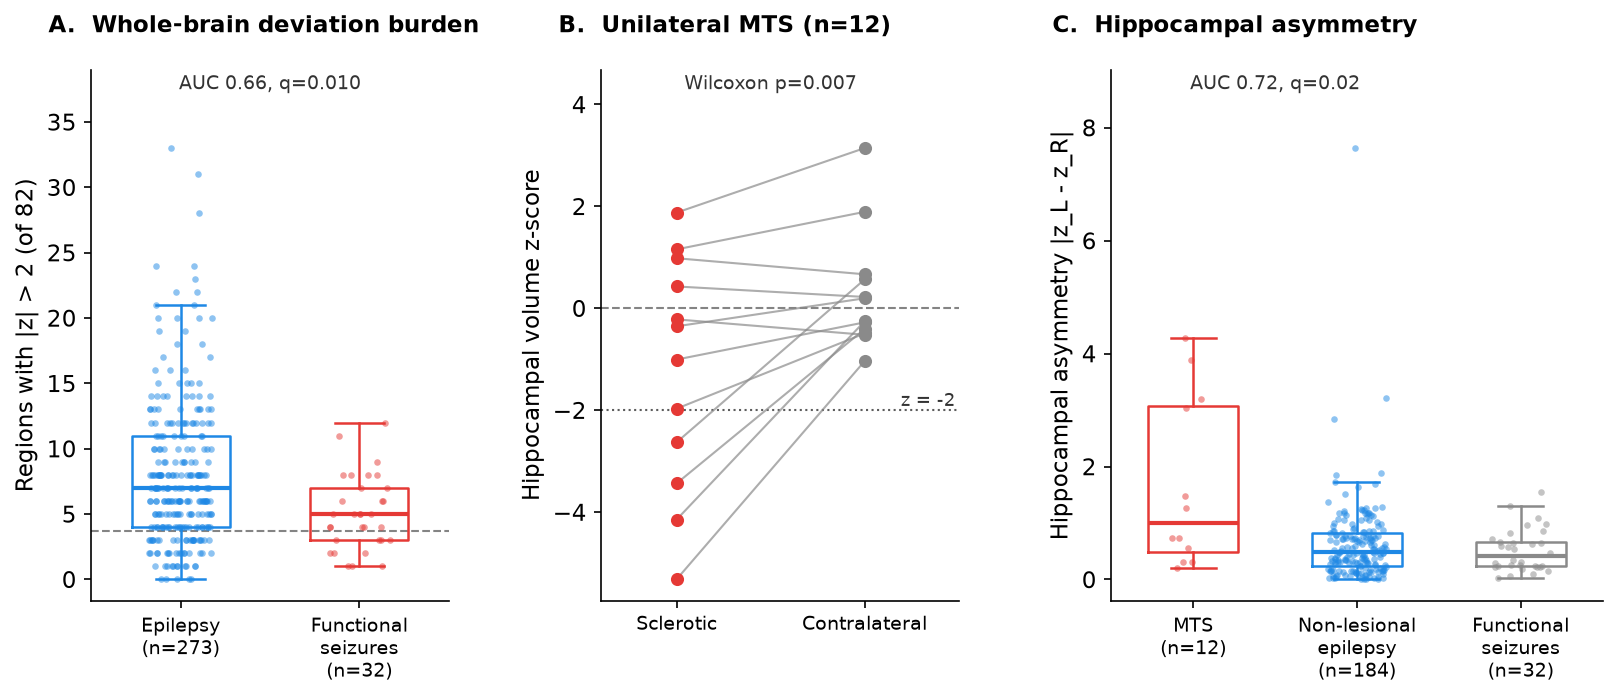

In [9]:
import matplotlib.pyplot as plt
plt.rcParams['figure.dpi'] = 150
plt.rcParams['font.size'] = 11
plt.rcParams['font.family'] = 'sans-serif'
COLOR_A, COLOR_B, COLOR_REF = '#1E88E5', '#E53935', '#8A8A8A'  # same pair as composite_figures.ipynb
INK = '#333333'
rng = np.random.default_rng(RNG_SEED)

def q_txt(q):
    return '<0.001' if q < 0.001 else (f'={q:.3f}' if q < 0.01 else f'={q:.2f}')

def style(ax, panel_label):
    for s in ['top', 'right']:
        ax.spines[s].set_visible(False)
    ax.text(-0.12, 1.06, panel_label, transform=ax.transAxes, fontsize=11, fontweight='bold',
            ha='left', va='bottom', clip_on=False)

def box_strip(ax, vals, x, color):
    vals = np.asarray(vals.dropna())
    ax.boxplot(vals, positions=[x], widths=0.55, showfliers=False,
               medianprops=dict(color=color, linewidth=2), boxprops=dict(color=color, linewidth=1.2),
               whiskerprops=dict(color=color, linewidth=1.2), capprops=dict(color=color, linewidth=1.2))
    ax.scatter(x + rng.uniform(-0.18, 0.18, len(vals)), vals, s=10, color=color, alpha=0.5, linewidths=0, zorder=3)

fig = plt.figure(figsize=(13, 4.6))
gs = fig.add_gridspec(1, 3, width_ratios=[0.8, 0.8, 1.1], wspace=0.38)
axA, axB, axC = (fig.add_subplot(gs[0, i]) for i in range(3))

# A: burden, epilepsy vs functional seizures
mg = split_groups(morph)
box_strip(axA, mg['Epilepsy']['n_abnormal'], 0, COLOR_A)
box_strip(axA, mg['FS']['n_abnormal'], 1, COLOR_B)
r = burden[(burden['Comparison'] == 'Epilepsy vs. Functional Seizures') &
           (burden['Domain'] == 'Whole-brain morphometry (82 ROIs)') & (burden['Measure'] == 'Regions with |z|>2')].iloc[0]
axA.text(0.5, 0.99, f"AUC {r['AUC']:.2f}, q{q_txt(r['q'])}", transform=axA.get_xaxis_transform(),
         ha='center', va='top', fontsize=9, color=INK)
axA.axhline(82 * 0.0455, color=INK, linestyle='--', linewidth=1, alpha=0.6, zorder=1)
axA.set_xticks([0, 1]); axA.set_xticklabels([f"Epilepsy\n(n={len(mg['Epilepsy'])})", f"Functional\nseizures\n(n={len(mg['FS'])})"], fontsize=9)
axA.set_ylabel('Regions with |z| > 2 (of 82)')
lo, hi = axA.get_ylim(); axA.set_ylim(lo, hi + 0.12 * (hi - lo))
style(axA, 'A.  Whole-brain deviation burden')

# B: sclerotic vs contralateral, unilateral MTS
for _, rr in mts.iterrows():
    axB.plot([0, 1], [rr['ipsi'], rr['contra']], color=COLOR_REF, linewidth=1, alpha=0.7, zorder=2)
axB.scatter(np.zeros(len(mts)), mts['ipsi'], s=28, color=COLOR_B, zorder=3)
axB.scatter(np.ones(len(mts)), mts['contra'], s=28, color=COLOR_REF, zorder=3)
axB.axhline(0, color=INK, linestyle='--', linewidth=1, alpha=0.6, zorder=1)
axB.axhline(-2, color=INK, linestyle=':', linewidth=1, alpha=0.8, zorder=1)
axB.text(1.48, -2, 'z = -2', ha='right', va='bottom', fontsize=8.5, color=INK)
axB.text(0.5, 0.99, f'Wilcoxon p={w.pvalue:.3f}', transform=axB.get_xaxis_transform(),
         ha='center', va='top', fontsize=9, color=INK)
axB.set_xticks([0, 1]); axB.set_xticklabels(['Sclerotic', 'Contralateral'], fontsize=9)
axB.set_xlim(-0.4, 1.5)
axB.set_ylabel('Hippocampal volume z-score')
lo, hi = axB.get_ylim(); axB.set_ylim(lo, hi + 0.12 * (hi - lo))
style(axB, f'B.  Unilateral MTS (n={len(mts)})')

# C: hippocampal asymmetry, MTS vs non-lesional (tested), functional seizures for reference
for x, (g, color) in enumerate([('MTS', COLOR_B), ('Non-lesional', COLOR_A), ('FS', COLOR_REF)]):
    box_strip(axC, hip_groups[g]['hip_asym'], x, color)
r = hip_table[(hip_table['Comparison'] == 'MTS vs. Non-Lesional Epilepsy') & (hip_table['Measure'] == '|Left - Right|')].iloc[0]
auc = float(r['AUC (95% CI)'].split(' ')[0])
axC.text(0.5, 0.99, f"AUC {auc:.2f}, q{q_txt(r['q'])}", transform=axC.get_xaxis_transform(),
         ha='center', va='top', fontsize=9, color=INK)
axC.set_xticks([0, 1, 2])
axC.set_xticklabels([f"MTS\n(n={len(hip_groups['MTS'])})", f"Non-lesional\nepilepsy\n(n={len(hip_groups['Non-lesional'])})",
                     f"Functional\nseizures\n(n={len(hip_groups['FS'])})"], fontsize=9)
axC.set_ylabel('Hippocampal asymmetry |z_L - z_R|')
lo, hi = axC.get_ylim(); axC.set_ylim(lo, hi + 0.12 * (hi - lo))
style(axC, 'C.  Hippocampal asymmetry')

plt.savefig('../outputs/figure_supp_burden_hippocampus.pdf', bbox_inches='tight', dpi=300)
plt.savefig('../outputs/figure_supp_burden_hippocampus.png', bbox_inches='tight', dpi=300)
plt.show()

## 7. Hippocampal Flag Rate: MTS vs Other Groups

How often a hippocampus falls below z = -2. In MTS: the sclerotic side (side known) and either side (side-blind,
the same rule applied to everyone). In the other groups: either side, i.e. the false-positive rate of the side-blind rule.

In [10]:
flag_rows = [{'Group': 'MTS, sclerotic side', 'n': len(mts), 'Below z=-2': int((mts['ipsi'] < -2).sum())},
             {'Group': 'MTS, either side', 'n': len(mts), 'Below z=-2': int((mts['hip_min'] < -2).sum())}]
for g, label in [('Non-lesional', 'Non-lesional epilepsy, either side'), ('FS', 'Functional seizures, either side')]:
    df = hip_groups[g]
    flag_rows.append({'Group': label, 'n': len(df), 'Below z=-2': int((df['hip_min'] < -2).sum())})
syn = morph[morph['group_1'] == 'syncope']
flag_rows.append({'Group': 'Syncope, either side', 'n': len(syn), 'Below z=-2': int((syn['hip_min'] < -2).sum())})
flags = pd.DataFrame(flag_rows)
flags['%'] = (100 * flags['Below z=-2'] / flags['n']).round(1)
flags

,Group,n,Below z=-2,%
0,"MTS, sclerotic side",12,4,33.3
1,"MTS, either side",12,4,33.3
2,"Non-lesional epilepsy, either side",184,9,4.9
3,"Functional seizures, either side",32,0,0.0
4,"Syncope, either side",25,1,4.0


## 8. Deviation Burden: Non-Lesional Epilepsy vs Functional Seizures

Section 3 repeated with epilepsy restricted to patients without a lesion on clinical MRI (`mri_lesion == 0`), the
comparison a clinician would need help with. Benjamini-Hochberg FDR across the six domain x measure tests, as in
Section 3. Followed by the Section 3b sex check on the same subset.

In [11]:
les_status = meta.set_index('SubjectID')['mri_lesion']
print('Lesional patients among functional seizures:', int(morph_groups['FS']['SubjectID'].map(les_status).sum()))
nonles_ids = set(morph_groups['Epilepsy'].loc[morph_groups['Epilepsy']['mri_lesion'] == 0, 'SubjectID'])
print(f"Epilepsy: {len(morph_groups['Epilepsy'])}, non-lesional: {len(nonles_ids)}")

rows = []
for dname, groups, n_units in domains:
    id_col = 'SubjectID' if 'SubjectID' in groups['Epilepsy'].columns else 'subject'
    epi_nl = groups['Epilepsy'][groups['Epilepsy'][id_col].isin(nonles_ids)]
    epi_les = groups['Epilepsy'][~groups['Epilepsy'][id_col].isin(nonles_ids)]
    for col, mlabel in measures:
        a, b = epi_nl[col], groups['FS'][col]
        auc, p = mwu_auc(a, b)
        lo, hi = bootstrap_auc_ci(a, b)
        f_auc, f_lo, f_hi = fold_auc(auc, lo, hi)
        fmt = (lambda v: f'{v:.0f}') if col == 'n_abnormal' else (lambda v: f'{v:.2f}')
        rows.append({'Domain': dname, 'Measure': mlabel, 'n': f'{len(a)} vs {len(b)}',
                     'Median: non-lesional vs FS (lesional epilepsy)': f'{fmt(a.median())} vs {fmt(b.median())} ({fmt(epi_les[col].median())})',
                     'AUC': f_auc, 'AUC (95% CI)': f'{f_auc:.3f} ({f_lo:.3f}-{f_hi:.3f})',
                     'Higher In': 'Non-lesional epilepsy' if auc >= 0.5 else 'FS', 'p': p})
nl_burden = pd.DataFrame(rows)
nl_burden['q'] = multipletests(nl_burden['p'], method='fdr_bh')[1]
nl_burden['p'] = nl_burden['p'].round(4); nl_burden['q'] = nl_burden['q'].round(4)
nl_burden = nl_burden.drop(columns='AUC')
nl_burden.to_csv('../outputs/table_burden_nonlesional.csv', index=False)
nl_burden

Lesional patients among functional seizures: 0
Epilepsy: 273, non-lesional: 184


,Domain,Measure,n,Median: non-lesional vs FS (lesional epilepsy),AUC (95% CI),Higher In,p,q
0,Whole-brain morphometry (82 ROIs),Regions with |z|>2,184 vs 32,6 vs 5 (9),0.623 (0.525-0.718),Non-lesional epilepsy,0.0265,0.0795
1,Whole-brain morphometry (82 ROIs),Mean |z|,184 vs 32,0.90 vs 0.84 (1.00),0.641 (0.536-0.736),Non-lesional epilepsy,0.0111,0.0667
2,"Tractometry, tract-level (18 series)",Regions with |z|>2,184 vs 32,0 vs 0 (0),0.522 (0.478-0.552),Non-lesional epilepsy,0.3789,0.5683
3,"Tractometry, tract-level (18 series)",Mean |z|,184 vs 32,0.43 vs 0.50 (0.50),0.531 (0.417-0.644),FS,0.5823,0.6987
4,"Tractometry, node-level (3,000 values)",Regions with |z|>2,184 vs 32,62 vs 64 (109),0.563 (0.439-0.682),Non-lesional epilepsy,0.2562,0.5123
5,"Tractometry, node-level (3,000 values)",Mean |z|,184 vs 32,0.67 vs 0.68 (0.73),0.505 (0.388-0.621),Non-lesional epilepsy,0.9304,0.9304


In [12]:
# Sex check on the non-lesional subset (as Section 3b)
e = morph_groups['Epilepsy'][morph_groups['Epilepsy']['SubjectID'].isin(nonles_ids)]
f = morph_groups['FS']
print(pd.crosstab(pd.concat([e.assign(g='Non-lesional epilepsy'), f.assign(g='FS')])['g'], pd.concat([e, f])['sex']))
sex_rows = []
for col, mlabel in measures:
    for sx in ['F', 'M']:
        a, b = e[e['sex'] == sx][col], f[f['sex'] == sx][col]
        auc, p = mwu_auc(a, b)
        sex_rows.append({'Measure': mlabel, 'Test': f'{sx} only', 'n': f'{len(a)} vs {len(b)}', 'AUC': round(auc, 3), 'p': round(p, 4)})
    num = sum(mwu_auc(e[e['sex'] == sx][col], f[f['sex'] == sx][col])[0] * (e['sex'] == sx).sum() * (f['sex'] == sx).sum() for sx in ['F', 'M'])
    den = sum((e['sex'] == sx).sum() * (f['sex'] == sx).sum() for sx in ['F', 'M'])
    sex_rows.append({'Measure': mlabel, 'Test': 'Sex-stratified AUC', 'n': f'{len(e)} vs {len(f)}', 'AUC': round(num / den, 3), 'p': np.nan})
    d = pd.concat([e.assign(is_epi=1), f.assign(is_epi=0)])
    d['r'] = rankdata(d[col])
    fit = smf.ols('r ~ is_epi + C(sex)', data=d).fit()
    sex_rows.append({'Measure': mlabel, 'Test': 'Rank regression, adjusted for sex', 'n': f'{len(e)} vs {len(f)}', 'AUC': np.nan, 'p': round(fit.pvalues['is_epi'], 4)})
pd.DataFrame(sex_rows)

sex                     F    M
g                             
FS                     25    7
Non-lesional epilepsy  84  100


,Measure,Test,n,AUC,p
0,Regions with |z|>2,F only,84 vs 25,0.616,0.0775
1,Regions with |z|>2,M only,100 vs 7,0.701,0.0762
2,Regions with |z|>2,Sex-stratified AUC,184 vs 32,0.637,NaN
3,Regions with |z|>2,"Rank regression, adjusted for sex",184 vs 32,NaN,0.0119
4,Mean |z|,F only,84 vs 25,0.598,0.1386
5,Mean |z|,M only,100 vs 7,0.796,0.0072
6,Mean |z|,Sex-stratified AUC,184 vs 32,0.648,NaN
7,Mean |z|,"Rank regression, adjusted for sex",184 vs 32,NaN,0.0088
